In [2]:
%pip install numpy pandas matplotlib seaborn scikit-learn xgboost optuna plotly anywidget

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import optuna

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, roc_auc_score, precision_recall_curve,
                             average_precision_score)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_sample_weight

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
print("xgboost", xgb.__version__, "| optuna", optuna.__version__)

xgboost 3.4.1 | optuna 5.0.0


## Part 1 – Cleaned dataset, encoding and target classes 

* `Order`, `PID`: identifiers
* `Alley`, `Pool QC`, `Misc Feature`: > 90 % "NA"
* `Garage Yr Blt`: correlation 0.83 with `Year Built`
* `Garage Cars`: correlation 0.89 with `Garage Area`
* For all other categorical columns "NA" means "feature not present" (no garage, no basement etc) → replaced by the category `"None"`.
* `Lot Frontage` (truly missing, 17 %) → median of the same `Neighborhood`.
* Numeric basement/garage/veneer columns that are NA because the feature does not exist → 0.
* `Gr Liv Area > 4000`: the five outliers from L1 → removed

In [4]:
initial = pd.read_csv("AmesHousing.csv", sep="\t")
print("Initial shape:", initial.shape)

def clean(df, drop_outliers=True):
    df = df.copy()
    # 1) identifiers and columns that are almost empty
    df = df.drop(columns=["Order", "PID", "Alley", "Pool QC", "Misc Feature",
                          "Garage Yr Blt", "Garage Cars"])
    # 2) outliers identified in L1
    if drop_outliers:
        df = df[df["Gr Liv Area"] <= 4000]
    
    # Missing values
    # 3) "NA" = feature not present -> category "None"
    cat_cols = df.select_dtypes(include="object").columns
    df[cat_cols] = df[cat_cols].fillna("None")
    df["Electrical"] = df["Electrical"].replace("None", df["Electrical"].mode()[0])  # 1 truly missing value
    # 4) numeric columns
    df["Lot Frontage"] = df.groupby("Neighborhood")["Lot Frontage"].transform(lambda s: s.fillna(s.median()))
    df["Lot Frontage"] = df["Lot Frontage"].fillna(df["Lot Frontage"].median())
    num_cols = df.select_dtypes(include="number").columns.drop("SalePrice")
    df[num_cols] = df[num_cols].fillna(0)
    return df

housing = clean(initial)
print("Cleaned shape:", housing.shape, "| remaining NaN:", int(housing.isna().sum().sum()))

Initial shape: (2930, 82)
Cleaned shape: (2925, 75) | remaining NaN: 0


,class,count,percent
0,<100k,237,8.1
1,100-130k,509,17.4
2,130-180k,1036,35.4
3,180-250k,684,23.4
4,250-400k,397,13.6
5,>=400k,62,2.1


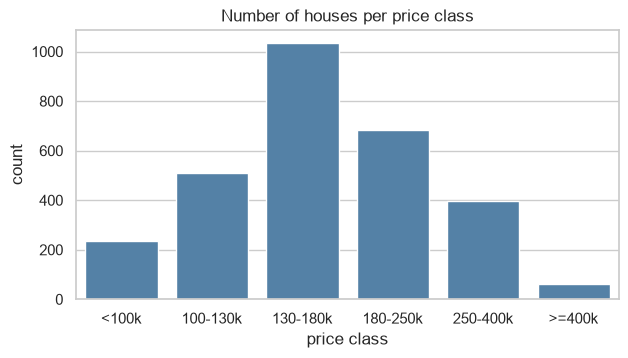

In [5]:
BINS = [0, 100_000, 130_000, 180_000, 250_000, 400_000, np.inf]
CLASS_NAMES = ["<100k", "100-130k", "130-180k", "180-250k", "250-400k", ">=400k"]

def make_target(df):
    # intervals [a, b): 100000 belongs to class 1, 400000 to class 5
    return pd.cut(df["SalePrice"], bins=BINS, right=False, labels=False).astype(int)

y_all = make_target(housing)
dist = pd.DataFrame({"class": CLASS_NAMES, "count": y_all.value_counts().sort_index().values})
dist["percent"] = (dist["count"] / len(y_all) * 100).round(1)
display(dist)

plt.figure(figsize=(7, 3.5))
sns.barplot(x=CLASS_NAMES, y=dist["count"], color="steelblue")
plt.title("Number of houses per price class"); plt.ylabel("count"); plt.xlabel("price class")
plt.show()


**Interpretation.** The classes are imbalanced: the middle class `130-180k` contains about 35 % of the houses, whereas `>=400k` has only 62 houses (2.1 %). This is why *accuracy alone is misleading* (always predicting `130-180k` would give 35 %), why we report **macro-averaged** metrics (every class counts equally), and why stratification and class weights are tested.

In [6]:
QUAL = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ORDINAL_MAPS = {
    "Exter Qual": QUAL, "Exter Cond": QUAL, "Bsmt Qual": QUAL, "Bsmt Cond": QUAL,
    "Heating QC": QUAL, "Kitchen Qual": QUAL, "Fireplace Qu": QUAL,
    "Garage Qual": QUAL, "Garage Cond": QUAL,
    "Bsmt Exposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFin Type 1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFin Type 2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "Functional": {"Sal": 1, "Sev": 2, "Maj2": 3, "Maj1": 4, "Mod": 5, "Min2": 6, "Min1": 7, "Typ": 8},
    "Garage Finish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Paved Drive": {"N": 0, "P": 1, "Y": 2},
    "Fence": {"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
    "Lot Shape": {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "Land Slope": {"Sev": 0, "Mod": 1, "Gtl": 2},
    "Utilities": {"ELO": 0, "NoSeWa": 1, "NoSewr": 2, "AllPub": 3},
    "Central Air": {"N": 0, "Y": 1},
}

def add_features(df):
    # combined features
    d = df.copy()
    d["TotalSF"]      = d["Total Bsmt SF"] + d["1st Flr SF"] + d["2nd Flr SF"]
    d["HouseAge"]     = d["Yr Sold"] - d["Year Built"]
    d["RemodAge"]     = d["Yr Sold"] - d["Year Remod/Add"]
    d["TotalBath"]    = d["Full Bath"] + 0.5 * d["Half Bath"] + d["Bsmt Full Bath"] + 0.5 * d["Bsmt Half Bath"]
    d["TotalPorchSF"] = d["Open Porch SF"] + d["Enclosed Porch"] + d["3Ssn Porch"] + d["Screen Porch"] + d["Wood Deck SF"]
    d["IsRemodeled"]  = (d["Year Remod/Add"] != d["Year Built"]).astype(int)
    d["QualxSF"]      = d["Overall Qual"] * d["Gr Liv Area"]
    return d

def build_features(df, nominal="onehot", engineer=False, drop_corr=False):
    d = df.drop(columns=["SalePrice"]).copy()
    d["MS SubClass"] = d["MS SubClass"].astype(str) 
    if engineer:
        d = add_features(d)
    for col, mp in ORDINAL_MAPS.items():
        d[col] = d[col].map(mp).astype(float)
    nom_cols = d.select_dtypes(include="object").columns.tolist()
    if nominal == "onehot":
        d = pd.get_dummies(d, columns=nom_cols, dtype=int)
    elif nominal == "label":
        for c in nom_cols:
            d[c] = d[c].astype("category").cat.codes
    elif nominal == "native":
        for c in nom_cols:
            d[c] = d[c].astype("category")
    if drop_corr:
        num = d.select_dtypes(include="number")
        corr = num.corr().abs()
        upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        to_drop = [c for c in upper.columns if (upper[c] > 0.9).any()]
        d = d.drop(columns=to_drop)
    d.columns = [str(c).replace("[", "(").replace("]", ")").replace("<", "lt") for c in d.columns]
    return d

X_all = build_features(housing)
print("Features after encoding:", X_all.shape[1])
print("Nominal columns one-hot encoded:", housing.drop(columns=["SalePrice"]).select_dtypes("object").columns.difference(list(ORDINAL_MAPS)).size + 1)
print("Ordinal columns mapped to integers:", len(ORDINAL_MAPS))
X_all.iloc[:3, :12]

Features after encoding: 236
Nominal columns one-hot encoded: 21
Ordinal columns mapped to integers: 20


,Lot Frontage,Lot Area,Lot Shape,Utilities,Land Slope,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,Exter Qual,Exter Cond
0,141.0,31770,2.0,3.0,2.0,6,5,1960,1960,112.0,3.0,3.0
1,80.0,11622,3.0,3.0,2.0,5,6,1961,1961,0.0,3.0,3.0
2,81.0,14267,2.0,3.0,2.0,6,6,1958,1958,108.0,3.0,3.0


In [7]:
# base settings of the model(200 succesive decision trees etc)
BASE_PARAMS = dict(n_estimators=200, learning_rate=0.1, max_depth=4, subsample=0.8,
                   colsample_bytree=0.8, min_child_weight=1, gamma=0, reg_lambda=1,
                   tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE)

def fit_model(params, X, y, weights=None, **kw):
    m = xgb.XGBClassifier(**params, **kw)
    m.fit(X, y, sample_weight=weights)
    return m

def scores(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, average="macro", zero_division=0),
                recall=recall_score(y_true, y_pred, average="macro", zero_division=0),
                macro_f1=f1_score(y_true, y_pred, average="macro", zero_division=0))

#K-Fold-Cross-Validation
def cv_eval(X, y, params=BASE_PARAMS, splitter=None, weight_mode=None, return_folds=False):
    splitter = splitter or StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    for tr, va in splitter.split(X, y):
        w = compute_sample_weight(weight_mode, y.iloc[tr]) if weight_mode == "balanced" else None
        if weight_mode == "sqrt":
            w = np.sqrt(compute_sample_weight("balanced", y.iloc[tr]))
        m = fit_model(params, X.iloc[tr], y.iloc[tr], w, **({"enable_categorical": True}
                      if any(str(t) == "category" for t in X.dtypes) else {}))
        r_va = scores(y.iloc[va], m.predict(X.iloc[va]))
        r_tr = scores(y.iloc[tr], m.predict(X.iloc[tr]))
        rows.append({**{f"val_{k}": v for k, v in r_va.items()}, "train_macro_f1": r_tr["macro_f1"],
                     "train_accuracy": r_tr["accuracy"]})
    df = pd.DataFrame(rows)
    return df if return_folds else df.agg(["mean", "std"]).T

def pm(series_mean, series_std, nd=3):
    return f"{series_mean:.{nd}f} ± {series_std:.{nd}f}"

## Part 2 – Train/test split 10 % vs 20 %, with and without stratification

acc_mean  acc_std  f1_mean  f1_std  train_f1  class5_in_test_min  class5_in_test_max
test_size stratified                                                                                      
10 %      False         0.7706   0.0137   0.7531  0.0134    0.9928                   2                  11
          True          0.7686   0.0252   0.7556  0.0441    0.9937                   6                   6
20 %      False         0.7648   0.0222   0.7458  0.0206    0.9952                   7                  16
          True          0.7791   0.0172   0.7603  0.0327    0.9957                  12                  12

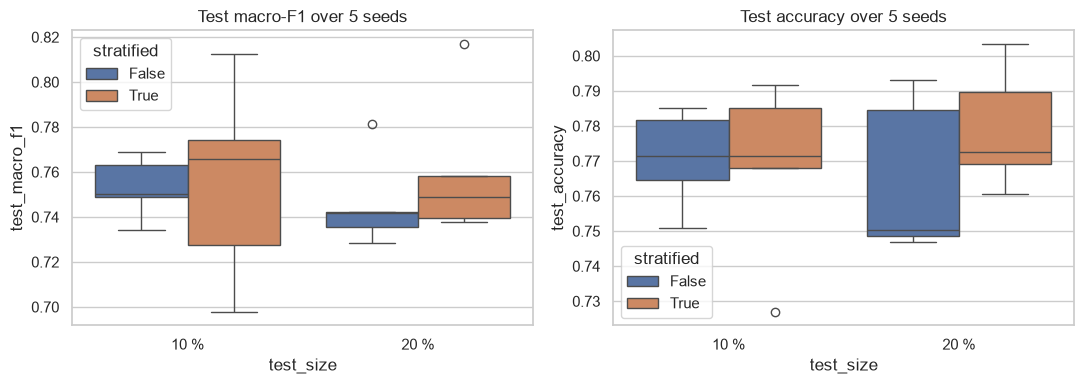

In [8]:
rows = []
for test_size in [0.10, 0.20]:
    for strat in [False, True]:
        for seed in range(5):
            Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=test_size, random_state=seed,
                                                  stratify=y_all if strat else None)
            m = fit_model(BASE_PARAMS, Xtr, ytr)
            te, tr = scores(yte, m.predict(Xte)), scores(ytr, m.predict(Xtr))
            rows.append(dict(test_size=f"{int(test_size*100)} %", stratified=strat, seed=seed,
                             test_accuracy=te["accuracy"], test_macro_f1=te["macro_f1"],
                             train_macro_f1=tr["macro_f1"], n_test=len(yte),
                             test_n_class5=int((yte == 5).sum())))
split_res = pd.DataFrame(rows)
summary = split_res.groupby(["test_size", "stratified"]).agg(
    acc_mean=("test_accuracy", "mean"), acc_std=("test_accuracy", "std"),
    f1_mean=("test_macro_f1", "mean"), f1_std=("test_macro_f1", "std"),
    train_f1=("train_macro_f1", "mean"),
    class5_in_test_min=("test_n_class5", "min"), class5_in_test_max=("test_n_class5", "max")).round(4)
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=split_res, x="test_size", y="test_macro_f1", hue="stratified", ax=ax[0])
ax[0].set_title("Test macro-F1 over 5 seeds")
sns.boxplot(data=split_res, x="test_size", y="test_accuracy", hue="stratified", ax=ax[1])
ax[1].set_title("Test accuracy over 5 seeds")
plt.tight_layout(); plt.show()

* **Overall Performance**: All four configurations reach a very similar test performance (macro-F1 ≈ 0.75–0.76, accuracy ≈ 0.77–0.78).
* **The Role of Stratification**: Stratification makes our test set stable and consistent. With stratification, the rare >=400k class always shows up the exact same number of times—6 times for a 10% test or 12 times for a 20% test. Without it, the count bounces around randomly between 2 and 11 (for 10%) or 7 and 16 (for 20%). If the test randomly gets only 2 rare houses, the score for that class becomes pretty much useless. The highest average macro-F1 was achieved using the 20% stratified setup (0.760). 
* **10% vs. 20% Test**: A 10% test set (≈ 293 houses) leaves more data for training (less bias), but the estimate is noisier (e.g., std of macro-F1 is 0.052 with stratification, with only 6 rare houses in the test set). A 20% test set gives a more reliable estimate and costs only a little training data.
* **Overfitting Issue**: The training macro-F1 is ≈ 0.99 while the test macro-F1 is ≈ 0.75: the model fits the training data almost perfectly 

## Part 3 – k-fold cross validation (k = 5 and k = 10), bias–variance trade-off

,k,splitter,val_accuracy,val_macro_f1,train_macro_f1,gap_train_minus_val,f1_range_over_folds
0,5,KFold,0.761 ± 0.018,0.750 ± 0.008,0.995,0.245,0.736 – 0.756
1,5,StratifiedKFold,0.770 ± 0.019,0.750 ± 0.026,0.995,0.246,0.711 – 0.775
2,10,KFold,0.774 ± 0.023,0.759 ± 0.016,0.993,0.234,0.733 – 0.776
3,10,StratifiedKFold,0.773 ± 0.028,0.756 ± 0.032,0.993,0.237,0.705 – 0.811


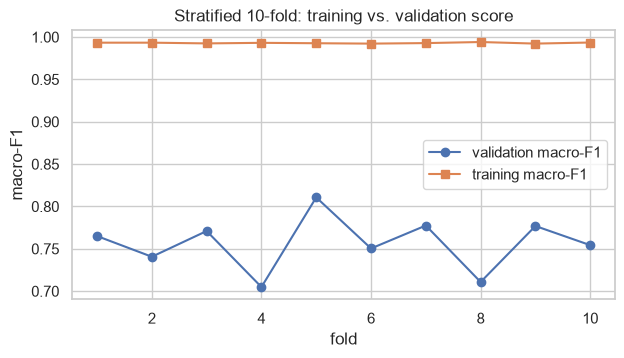

In [9]:
rows = []
for k in [5, 10]:
    for name, SplitCls in [("KFold", KFold), ("StratifiedKFold", StratifiedKFold)]:
        folds = cv_eval(X_all, y_all, BASE_PARAMS, SplitCls(k, shuffle=True, random_state=RANDOM_STATE), return_folds=True)
        rows.append(dict(k=k, splitter=name,
                         val_accuracy=pm(folds.val_accuracy.mean(), folds.val_accuracy.std()),
                         val_macro_f1=pm(folds.val_macro_f1.mean(), folds.val_macro_f1.std()),
                         train_macro_f1=round(folds.train_macro_f1.mean(), 3),
                         gap_train_minus_val=round(folds.train_macro_f1.mean() - folds.val_macro_f1.mean(), 3),
                         f1_range_over_folds=f"{folds.val_macro_f1.min():.3f} – {folds.val_macro_f1.max():.3f}"))
        if k == 10 and name == "StratifiedKFold":
            fold_plot = folds
cv_table = pd.DataFrame(rows)
display(cv_table)

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, 11), fold_plot.val_macro_f1, "o-", label="validation macro-F1")
plt.plot(range(1, 11), fold_plot.train_macro_f1, "s-", label="training macro-F1")
plt.xlabel("fold"); plt.ylabel("macro-F1"); plt.title("Stratified 10-fold: training vs. validation score")
plt.legend(); plt.show()

* **Cross-Validation**: Instead of doing just one random split, cross-validation tests every house on validation once. This gives us a much more reliable average and standard deviation. Our validation macro-F1 ends up around 0.74–0.76, which matches what we saw in the previous split experiments.   
* **k = 5 vs. k = 10**: When we use $k = 10$, the model trains on 90% of the data instead of 80%, so the score is slightly higher and less pessimistic (lower bias). However, because each validation chunk is smaller (~293 houses with only about 6 rare houses), the scores bounce around a lot more between folds (ranging from 0.6961 to 0.803), meaning higher variance. Plus, $k = 10$ takes twice as long to compute.   
* **KFold vs. StratifiedKFold**: The average scores are pretty much the same (within one standard deviation). Still, stratification is the safer and better choice because it makes sure the rare class is always properly balanced in every fold.   
* **Bias-Variance Trade-off**: There is a huge gap here—our training macro-F1 is around 0.99, while validation drops to about 0.75. This means the model has very low bias but high variance, basically memorizing the training data instead of generalizing (overfitting). To fix this, we'd normally need more data, stronger regularization, or simpler trees (which we'll test in Part 7).

**Fixed split strategy**: From now on, we stick to a single, fixed 80% / 20% stratified split so that the test set remains completely untouched until the final evaluation. All model tuning, hyperparameter choices, and Optuna searches will be done exclusively using 5-fold stratified cross-validation on the training portion only, keeping our test results completely honest and unbiased.

In [10]:
idx_train, idx_test = train_test_split(housing.index, test_size=0.20, random_state=RANDOM_STATE,
                                       stratify=y_all)
y_train, y_test = y_all.loc[idx_train], y_all.loc[idx_test]
X_train, X_test = X_all.loc[idx_train], X_all.loc[idx_test]
print("train:", X_train.shape, "| test:", X_test.shape)
print(pd.DataFrame({"train %": (y_train.value_counts(normalize=True).sort_index()*100).round(1),
                    "test %": (y_test.value_counts(normalize=True).sort_index()*100).round(1)}))

train: (2340, 236) | test: (585, 236)
           train %  test %
SalePrice                 
0              8.1     8.2
1             17.4    17.4
2             35.4    35.4
3             23.4    23.4
4             13.6    13.5
5              2.1     2.1


## Part 4 – Trees and Feature Importance

In this part we look inside the XGBoost model: how many boosting rounds it needs, what its trees look like, and which features it relies on.

**Setup.** For a 6-class problem XGBoost builds **6 trees per boosting round** (one per class, each producing a raw score/logit for its class). The trees are stored in the order `round 0: class 0..5, round 1: class 0..5, ...`. The tree for round $r$ and class $c$ therefore has the index

$$\text{tree index} = r \cdot 6 + c .$$

Steps:

1. **Early stopping** on a validation set that is split off the *training* data (the test set stays untouched until the final evaluation) to find a suitable number of rounds.
2. **First tree and best tree.**
3. **Feature importance** by *gain* and by *split count*.

In [35]:
# Validation set carved out of the TRAINING data only (the test set stays untouched)
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print("Fit:", X_fit.shape)
print("Validation:", X_val.shape)

Fit: (1872, 236)
Validation: (468, 236)


Best iteration (0-based round): 240
Rounds actually trained       : 271 (best + 30 patience rounds)
Trees in the booster          : 1626
Best validation mlogloss      : 0.601
Validation accuracy: 0.724 | validation macro-F1: 0.699


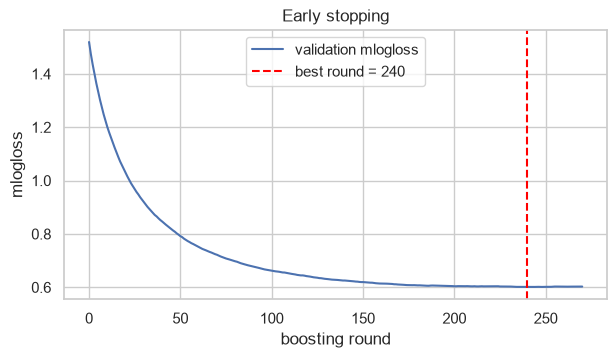

In [36]:
N_CLASSES = len(CLASS_NAMES)

EARLY_PARAMS = {
    **BASE_PARAMS,
    "n_estimators": 1000,          # upper limit, early stopping decides the real number
    "learning_rate": 0.05,
    "max_depth": 4,
    "early_stopping_rounds": 30,
    "eval_metric": "mlogloss",
}

model = xgb.XGBClassifier(**EARLY_PARAMS)
model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)

best_round = model.best_iteration                 # 0-based boosting round
n_rounds_trained = model.get_booster().num_boosted_rounds()

print("Best iteration (0-based round):", best_round)
print("Rounds actually trained       :", n_rounds_trained, "(best + 30 patience rounds)")
print("Trees in the booster          :", n_rounds_trained * N_CLASSES)
print("Best validation mlogloss      :", round(model.best_score, 4))

val_pred = model.predict(X_val)   # uses the best iteration automatically
print("Validation accuracy:", round(accuracy_score(y_val, val_pred), 3),
      "| validation macro-F1:", round(f1_score(y_val, val_pred, average="macro"), 3))

# Validation loss curve
evals = model.evals_result()["validation_0"]["mlogloss"]
plt.figure(figsize=(7, 3.5))
plt.plot(evals, label="validation mlogloss")
plt.axvline(best_round, color="red", ls="--", label=f"best round = {best_round}")
plt.xlabel("boosting round"); plt.ylabel("mlogloss"); plt.title("Early stopping")
plt.legend(); plt.show()

**Interpretation of early stopping.** The validation log-loss reaches its minimum at round **[best_round]**; after that it no longer improves for 30 rounds and training stops. This means that with `learning_rate = 0.05` and `max_depth = 4`, about [best_round + 1] rounds ([6 × (best_round + 1)] trees) are enough, and adding more would mostly fit noise (overfitting, see Part 3). Note that `predict()` automatically uses only the trees up to the best round, although the booster still contains the extra 30 patience rounds.

In [13]:
import shutil
print(shutil.which("dot"))

C:\Program Files (x86)\Graphviz\bin\dot.EXE


In [14]:

%pip install graphviz


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### 4.1 Decision tree visualization

We plot two trees of the **same class** so they are comparable: the **first tree** (round 0) and the **best tree** (the tree of the best round found by early stopping). We choose class 2 (`130-180k`), the largest class. Each inner node shows a split condition `feature < threshold`, the leaves show the leaf value (a contribution to the raw score of this class, which is added up over all rounds and then turned into probabilities by the softmax).

A single tree is only a *weak* learner: the prediction of the model is the sum of all trees of a class, so one tree does not explain the full model.

First tree: round 0, class 2 (130-180k) -> index 2
Best tree : round 240, class 2 (130-180k) -> index 1442


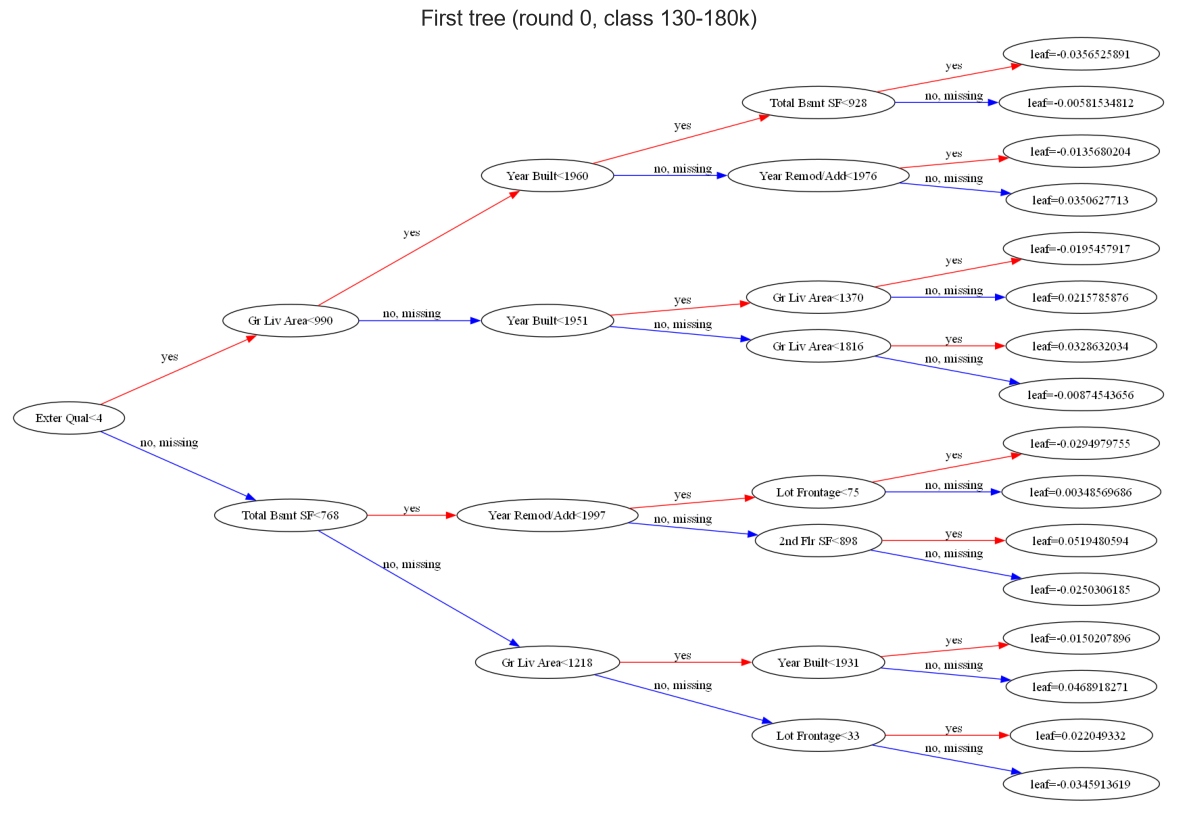

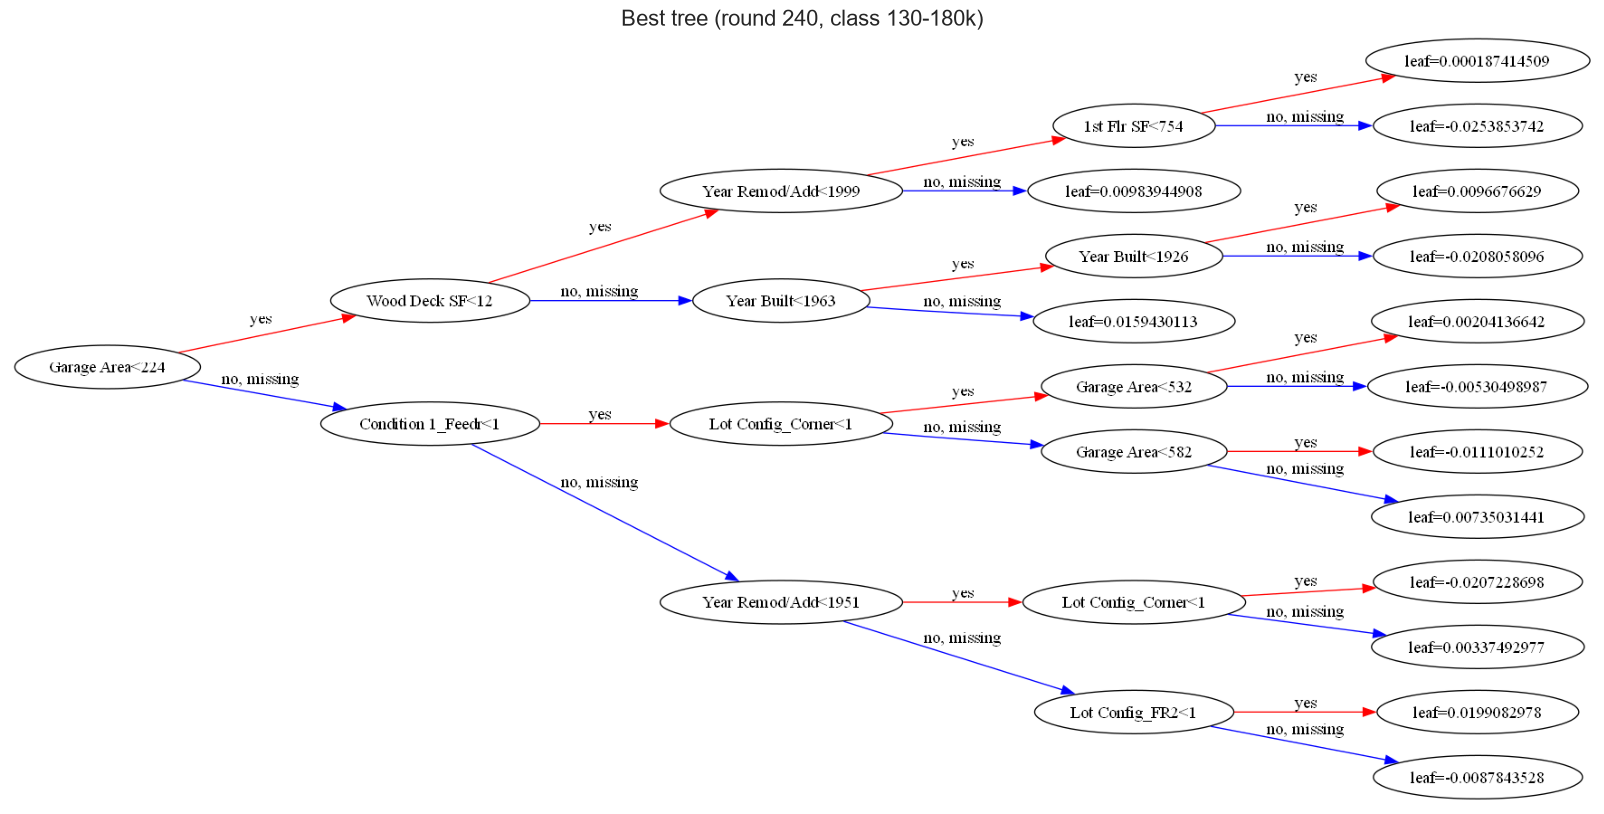

In [37]:
# NOTE: plot_tree needs the graphviz Python package AND the Graphviz binary
#       (pip install graphviz; plus e.g. `conda install graphviz` or the installer from graphviz.org)
PLOT_CLASS = 2   # 130-180k, the largest class

def tree_index(round_, cls, n_classes=N_CLASSES):
    """Index of the tree of boosting round `round_` for class `cls`."""
    return round_ * n_classes + cls

first_idx = tree_index(0, PLOT_CLASS)
best_idx  = tree_index(best_round, PLOT_CLASS)
print(f"First tree: round 0, class {PLOT_CLASS} ({CLASS_NAMES[PLOT_CLASS]}) -> index {first_idx}")
print(f"Best tree : round {best_round}, class {PLOT_CLASS} ({CLASS_NAMES[PLOT_CLASS]}) -> index {best_idx}")

for idx, title in [(first_idx, f"First tree (round 0, class {CLASS_NAMES[PLOT_CLASS]})"),
                   (best_idx,  f"Best tree (round {best_round}, class {CLASS_NAMES[PLOT_CLASS]})")]:
    fig, ax = plt.subplots(figsize=(24, 10))
    xgb.plot_tree(model, num_trees=idx, rankdir="LR", ax=ax)
    ax.set_title(title, fontsize=16)
    plt.show()

**Interpretation of the trees.**

* **First tree (round 0):** it only has to explain the very first residuals, so it splits on the strongest and most general predictors: [e.g. `Overall Qual`, `Gr Liv Area`, `Total Bsmt SF`, ... fill in from your plot]. Its leaf values are comparatively large, because it makes the biggest correction to the initial constant prediction.
* **Best tree (round [best_round]):** later trees fit what is left over after all previous rounds. They typically use *more specific* features (e.g. [neighborhood dummies, garage or lot features, ...]) and have **smaller leaf values**, because with `learning_rate = 0.05` each tree only makes a small correction.
* Both trees have depth at most 4 (`max_depth = 4`), so each uses few rules. The model's strength comes from summing hundreds of such small trees (boosting), not from any single tree.
* Trees of class 2 are only part of the model: every round also has one tree per other class, and the softmax over all six sums gives the final class probabilities.

### 4.2 Feature importance

We compare two importance measures from the XGBoost booster:

* **Gain** – the *average* improvement of the loss obtained from splits that use the feature. It measures how *useful* a feature is when it is used. (We also show `total_gain`, which is gain summed over all splits and therefore also reflects how often the feature is used.)
* **Split** (`weight` in the XGBoost API) – the *number of times* the feature is used for a split over all trees. It measures how *often* a feature is used.

The two can disagree: a continuous feature with many possible thresholds is used in many splits (high split count) even if each split helps little, while a strong binary or ordinal predictor may be used rarely but with a high gain.

Feature importance describes how the *model* uses the features; it does not prove a causal effect on the price.

Features used in at least one split: 169 of 236


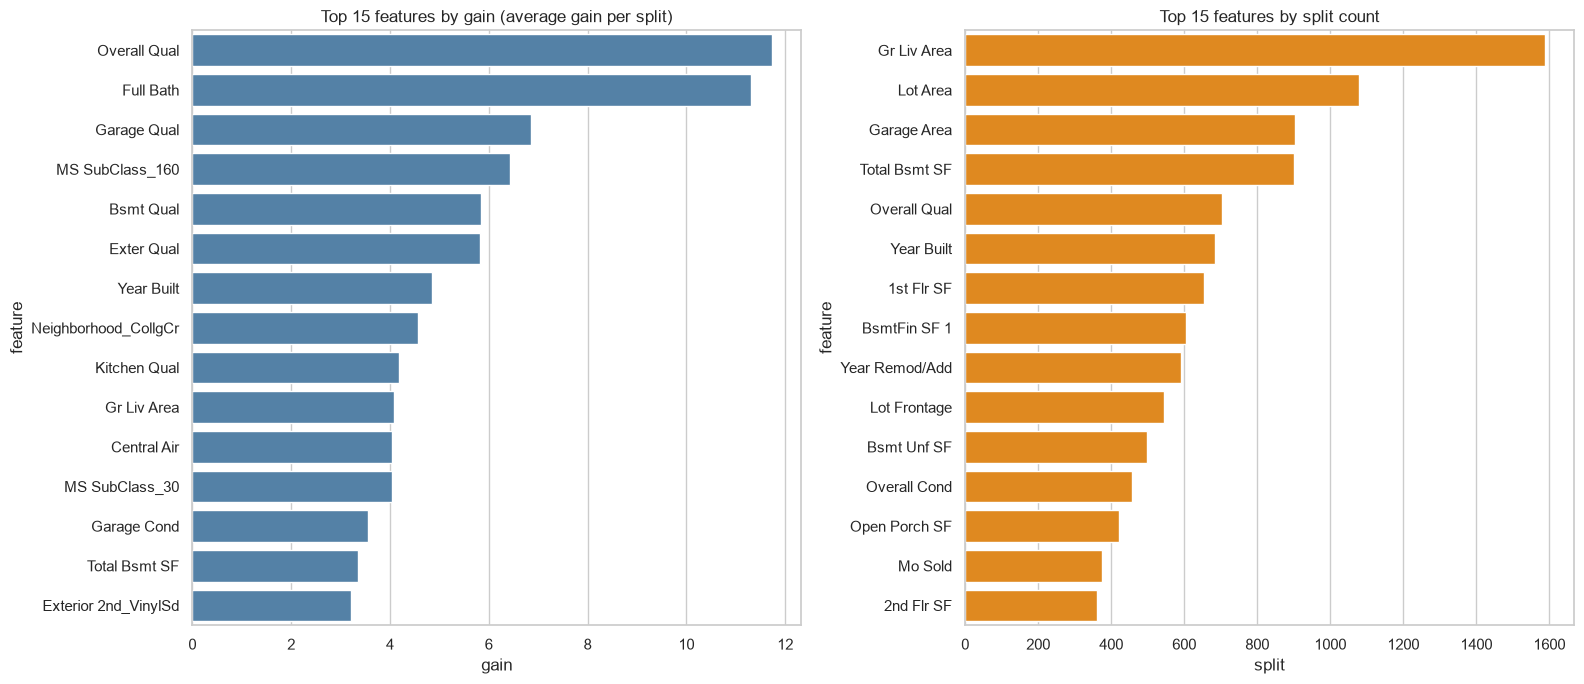

,feature,gain,total_gain,split,rank_gain,rank_split
5,Overall Qual,11.74,8239.04,702.0,1.0,5.0
29,Full Bath,11.31,1074.66,95.0,2.0,36.0
40,Garage Qual,6.85,431.80,63.0,3.0,47.0
55,MS SubClass_160,6.42,51.36,8.0,4.0,126.0
12,Bsmt Qual,5.85,1433.43,245.0,5.0,18.0
10,Exter Qual,5.82,546.84,94.0,6.0,38.0
7,Year Built,4.84,3306.44,683.0,7.0,6.0
92,Neighborhood_CollgCr,4.57,255.97,56.0,8.0,48.0
33,Kitchen Qual,4.17,859.57,206.0,9.0,23.0
26,Gr Liv Area,4.09,6490.84,1588.0,10.0,1.0


Overlap of the two top-15 lists: 4 features -> ['Gr Liv Area', 'Overall Qual', 'Total Bsmt SF', 'Year Built']


In [38]:
booster = model.get_booster()
gain       = booster.get_score(importance_type="gain")          # average gain per split
total_gain = booster.get_score(importance_type="total_gain")    # summed gain
split      = booster.get_score(importance_type="weight")        # number of splits

importance = pd.DataFrame({"feature": list(X_fit.columns)})
importance["gain"]       = importance["feature"].map(gain).fillna(0)
importance["total_gain"] = importance["feature"].map(total_gain).fillna(0)
importance["split"]      = importance["feature"].map(split).fillna(0)

print(f"Features used in at least one split: {(importance['split'] > 0).sum()} of {len(importance)}")

top_gain  = importance.sort_values("gain", ascending=False).head(15)
top_split = importance.sort_values("split", ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.barplot(data=top_gain, x="gain", y="feature", color="steelblue", ax=axes[0])
axes[0].set_title("Top 15 features by gain (average gain per split)")
sns.barplot(data=top_split, x="split", y="feature", color="darkorange", ax=axes[1])
axes[1].set_title("Top 15 features by split count")
plt.tight_layout(); plt.show()

# Ranking comparison
importance["rank_gain"]  = importance["gain"].rank(ascending=False, method="min")
importance["rank_split"] = importance["split"].rank(ascending=False, method="min")
display(importance.sort_values("gain", ascending=False).head(15)
        [["feature", "gain", "total_gain", "split", "rank_gain", "rank_split"]].round(2))

overlap = set(top_gain.feature) & set(top_split.feature)
print(f"Overlap of the two top-15 lists: {len(overlap)} features -> {sorted(overlap)}")

**Interpretation of the feature importance.**

* **Gain:** The most useful features are [e.g. `Overall Qual`, `Gr Liv Area`, `Total Bsmt SF`, `Garage Area`, `Exter Qual`, `Kitchen Qual`, ... fill in from your plot]. This fits the intuition: overall quality and living area are the strongest drivers of price, and the ordinal quality ratings are compact, informative features. [Mention if the highest gain comes from a binary/one-hot feature, e.g. a neighborhood dummy for expensive areas, which separates the top class well.]
* **Split count:** The most frequently used features are [e.g. `Lot Area`, `Gr Liv Area`, `Year Built`, `Lot Frontage`, ...]. These are mostly **continuous features with many possible thresholds**, which the trees can split in many places. They are used often, but each individual split brings less gain than a split on `Overall Qual`.
* **Why the rankings differ:** split count rewards features that offer many split points, gain rewards features whose splits really reduce the loss. The overlap of the two top-15 lists is [overlap size] features, so the two views are complementary, and gain is the more reliable indicator of predictive relevance.
* **Many one-hot columns are unused:** only [n] of [total] features appear in any split. Rare categories (e.g. rare `MS Zoning`, `Exterior`, or `Sale Type` values) hardly matter. This suggests that feature selection or a more compact encoding could be tried in Part 6.
* **Caveats:** importance is calculated on the training data and is influenced by correlated features (e.g. `Gr Liv Area`, `TotalSF`, `1st Flr SF`): the importance is shared between them. It also says nothing about causality.

## Part 5 – Metrics, curves and optimal thresholds

In this part we evaluate the XGBoost classifier on the **test set**, which has not been used for training, early stopping or any model choice.

**Model.** We use the settings found by early stopping in Part 4 (`learning_rate = 0.05`, `max_depth = 4`, number of rounds = best iteration + 1), but now trained on the **whole training set**. The features are the baseline encoding (S1: ordinal mapping + one-hot). In Part 6 the other preparation strategies were within the noise of this baseline, so we keep S1.

**Metrics.**
* **Accuracy** – share of correctly classified houses.
* **Precision / Recall / F1** – per class and as **macro** average (every class has the same weight, which matters because `>=400k` has only about 2 % of the houses).
* **Confusion matrix** – which classes are confused with which.
* **ROC curve and AUC** (one-vs-rest) – ranking quality of the predicted probability of a class against all others, independent of a threshold.
* **Precision–Recall curve and average precision (AP)** (one-vs-rest) – more informative than ROC for rare classes.
* **Optimal thresholds** – for each class the probability threshold with the best F1. To avoid leakage they are determined on **out-of-fold predictions of the training set** and only then applied to the test set.

In [42]:
# ---- 5.0 Final model: early-stopping settings, trained on the whole training set ----
FINAL_PARAMS = {
    **BASE_PARAMS,
    "learning_rate": 0.05,                       # same as in the early-stopping run (Part 4)
    "n_estimators": model.best_iteration + 1,    # number of rounds found by early stopping
    "eval_metric": "mlogloss",
}
print("Rounds:", FINAL_PARAMS["n_estimators"])

final_model = fit_model(FINAL_PARAMS, X_train, y_train)

y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)
classes = list(range(len(CLASS_NAMES)))
y_test_bin = label_binarize(y_test, classes=classes)

Rounds: 241


### 5.1 Precision, recall, F1 and accuracy

In [43]:
report = classification_report(y_test, y_pred, labels=classes, target_names=CLASS_NAMES,
                               zero_division=0, output_dict=True)
display(pd.DataFrame(report).T.round(3))

te = scores(y_test, y_pred)
tr = scores(y_train, final_model.predict(X_train))
summary = pd.DataFrame({"train": tr, "test": te}).T.round(3)
summary.columns = ["accuracy", "precision (macro)", "recall (macro)", "macro-F1"]
display(summary)

,precision,recall,f1-score,support
<100k,0.780,0.667,0.719,48.000
100-130k,0.739,0.667,0.701,102.000
130-180k,0.762,0.865,0.810,207.000
180-250k,0.775,0.730,0.752,137.000
250-400k,0.793,0.823,0.807,79.000
>=400k,1.000,0.500,0.667,12.000
accuracy,0.769,0.769,0.769,0.769
macro avg,0.808,0.708,0.743,585.000
weighted avg,0.772,0.769,0.767,585.000


,accuracy,precision (macro),recall (macro),macro-F1
train,0.972,0.980,0.979,0.980
test,0.769,0.808,0.708,0.743


**Interpretation of the metrics.**

* On the test set the model reaches an accuracy of **[acc]** and a macro-F1 of **[macro-F1]**. This is in line with the cross-validation results of Parts 3 and 6 ([≈0.75]), so the CV estimate was realistic and the test set has not been "overfitted".
* The **training** scores are much higher ([train macro-F1]) than the test scores. The model still memorizes the training data (low bias, high variance, see Part 3), even with early stopping and a moderate depth.
* **Per class:** the best F1 is reached for [e.g. the extreme classes `<100k` and/or the large middle class `130-180k`]. The weakest classes are [e.g. `180-250k` / `250-400k` / `>=400k`]. The rare class `>=400k` has only [12] test houses, so its precision, recall and F1 have a large uncertainty: one more or less correct house changes the recall by about [8] percentage points.
* Macro-averaged values are lower than accuracy because the weak classes count as much as the large ones.


**5.2 Confusion Matrix**

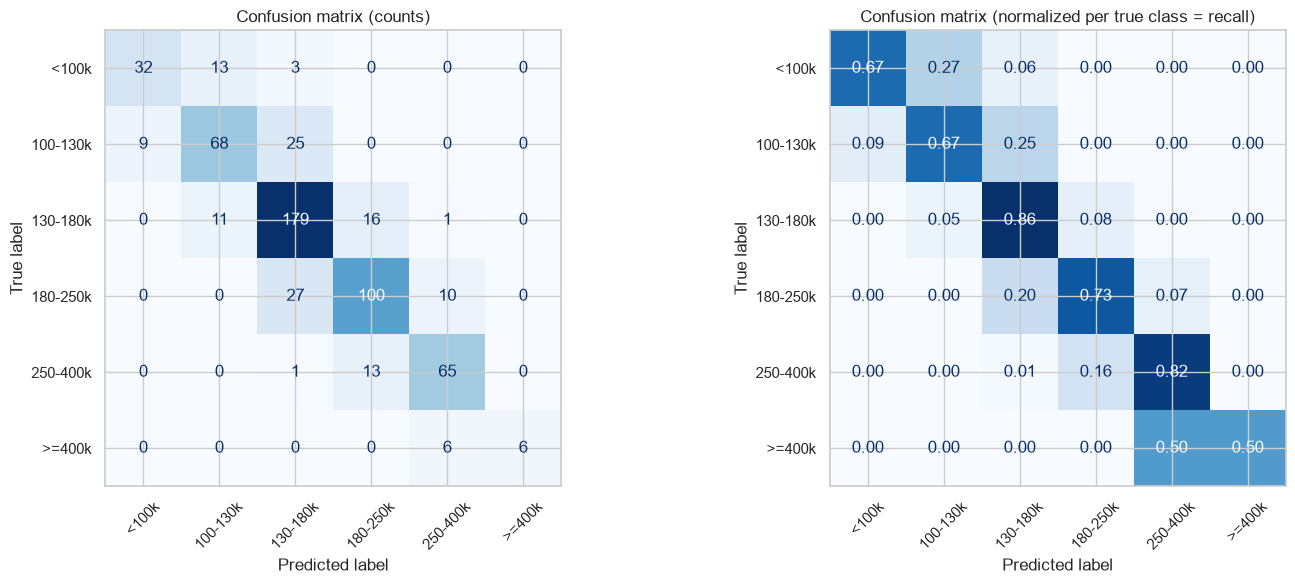

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=classes, display_labels=CLASS_NAMES,
                                        cmap="Blues", xticks_rotation=45, ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=classes, display_labels=CLASS_NAMES,
                                        normalize="true", values_format=".2f",
                                        cmap="Blues", xticks_rotation=45, ax=axes[1], colorbar=False)
axes[1].set_title("Confusion matrix (normalized per true class = recall)")
plt.tight_layout(); plt.show()

**Interpretation of the confusion matrix.**

* Most errors are **between neighbouring price classes** (e.g. `130-180k` ↔ `180-250k`). This is expected: the classes are cut from a continuous price at arbitrary boundaries, so a house at 178 000 € and one at 182 000 € are almost identical but belong to different classes. These errors are "small" in terms of price, even though the classifier counts them as fully wrong.
* Confusions between **distant** classes (e.g. `<100k` vs `>=250k`) are [rare / absent], which shows that the model has learned the order of magnitude of the price well.
* The normalized matrix shows the recall per class on the diagonal: [class X: value] is recognized best, [class Y: value] worst. The rare class `>=400k` is mostly confused with [`250-400k`], i.e. the model tends to place very expensive houses one class too low.
* Because the target was created by binning a continuous variable, the problem is really **ordinal**. A regression model followed by binning, or an ordinal approach, could use this extra information (not required here).

### 5.3 ROC curves (one-vs-rest)

For each class the predicted probability of this class is used as a score to separate it from the other five classes. The **macro-average** ROC is the mean of the six interpolated curves.

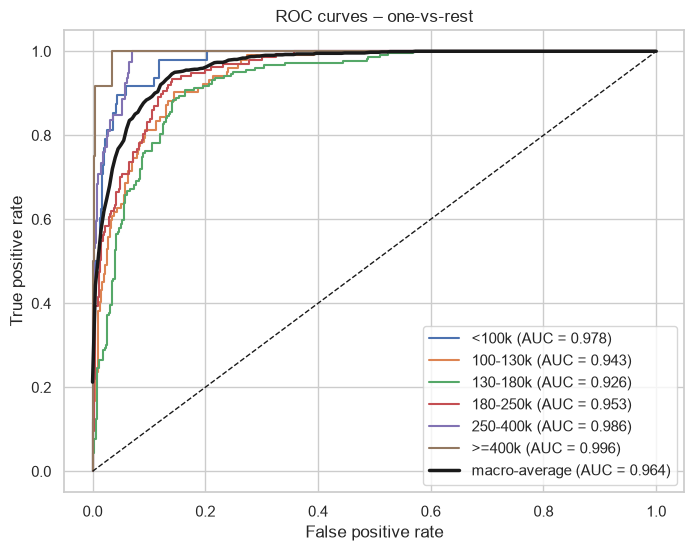

Macro ROC-AUC (OvR): 0.964


In [45]:
fpr_grid = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(8, 6))
tprs = []
for i, name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
    tprs.append(np.interp(fpr_grid, fpr, tpr))
macro_tpr = np.mean(tprs, axis=0)
ax.plot(fpr_grid, macro_tpr, "k-", lw=2.5, label=f"macro-average (AUC = {auc(fpr_grid, macro_tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves – one-vs-rest"); ax.legend(loc="lower right")
plt.show()

print("Macro ROC-AUC (OvR):", round(roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro"), 3))

### 5.4 Precision–Recall curves (one-vs-rest)

The dashed lines show the *no-skill* level, which equals the share of the class in the test set. A curve far above this line means that the class is recognized much better than by chance.

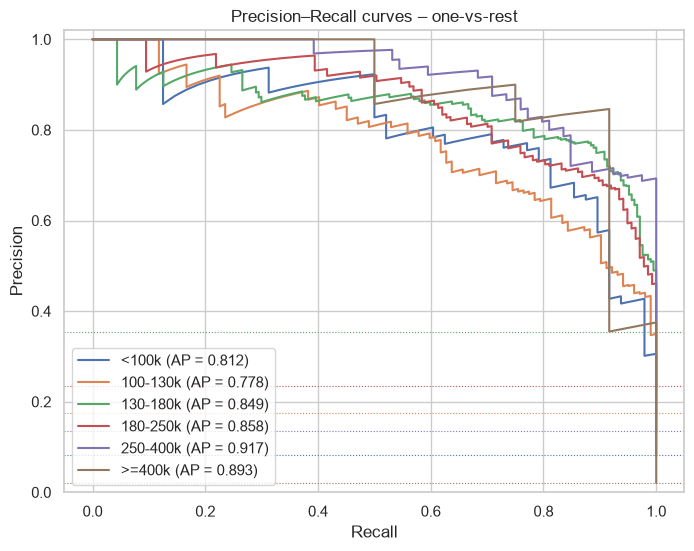

,class,AUC,AP,no_skill,support
0,<100k,0.978,0.812,0.082,48
1,100-130k,0.943,0.778,0.174,102
2,130-180k,0.926,0.849,0.354,207
3,180-250k,0.953,0.858,0.234,137
4,250-400k,0.986,0.917,0.135,79
5,>=400k,0.996,0.893,0.021,12


Macro AP: 0.851 | Macro AUC: 0.964


In [46]:
fig, ax = plt.subplots(figsize=(8, 6))
ap_rows = []
for i, name in enumerate(CLASS_NAMES):
    p, r, _ = precision_recall_curve(y_test_bin[:, i], y_prob[:, i])
    ap = average_precision_score(y_test_bin[:, i], y_prob[:, i])
    line, = ax.plot(r, p, label=f"{name} (AP = {ap:.3f})")
    ax.axhline(y_test_bin[:, i].mean(), color=line.get_color(), ls=":", lw=0.8)
    ap_rows.append(dict(**{"class": name}, AUC=roc_auc_score(y_test_bin[:, i], y_prob[:, i]),
                        AP=ap, no_skill=y_test_bin[:, i].mean(), support=int(y_test_bin[:, i].sum())))
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_ylim(0, 1.02)
ax.set_title("Precision–Recall curves – one-vs-rest"); ax.legend(loc="lower left")
plt.show()

auc_ap = pd.DataFrame(ap_rows).round(3)
display(auc_ap)
print("Macro AP:", round(auc_ap.AP.mean(), 3), "| Macro AUC:", round(auc_ap.AUC.mean(), 3))

**Interpretation of ROC and PR curves.**

* The ROC-AUC values are high for all classes (macro [≈0.95–0.97]). The model ranks houses of a class far above houses of other classes. The best separated classes are the **extreme ones** (`<100k`, `>=400k`: AUC [..]) because their neighbours are only on one side; the **middle classes** (`130-180k`, `180-250k`) are the hardest to separate (AUC [..]), since they are bounded by classes on both sides.
* ROC curves are **optimistic for rare classes**: for `>=400k` the false positive rate stays small simply because there are very many negatives. The **PR curves** are more honest: AP is [value] for `>=400k` compared with a no-skill level of only [≈0.02], and [value] for the large classes (no-skill [≈0.3]).
* The PR curve of the rare class is **jagged** because it is based on only [12] positive test houses; every single house moves the curve visibly. Differences between classes of a few hundredths of AP should therefore not be over-interpreted.
* The high AUC/AP compared with a moderate F1 indicates that the **ranking is good, but the default decision rule (argmax) is not optimal for every class**. This motivates the threshold search below.

### 5.5 Precision–Recall thresholds with the best (macro-)F1

For each class (one-vs-rest) the F1 score is computed for all thresholds of the PR curve,

$$F_1(t) = \frac{2\,P(t)\,R(t)}{P(t)+R(t)},$$

and the threshold with the maximum F1 is selected. To avoid **leakage**, the thresholds are determined on **out-of-fold probabilities of the training set** (5-fold, stratified) and are then applied unchanged to the test set.

To obtain one multiclass prediction from the six class thresholds $t_c$ we predict $\arg\max_c \; p_c / t_c$, i.e. the class whose probability is largest relative to its own threshold.

In [47]:
# Out-of-fold probabilities on the training set
oof_prob = np.zeros((len(y_train), len(classes)))
for tr_idx, va_idx in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train):
    m = fit_model(FINAL_PARAMS, X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    oof_prob[va_idx] = m.predict_proba(X_train.iloc[va_idx])
y_train_bin = label_binarize(y_train, classes=classes)

# Best-F1 threshold per class (one-vs-rest) on the out-of-fold data
rows, best_thr = [], np.zeros(len(classes))
for i, name in enumerate(CLASS_NAMES):
    p, r, t = precision_recall_curve(y_train_bin[:, i], oof_prob[:, i])
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    j = int(f1.argmax())
    best_thr[i] = t[j]
    rows.append({"class": name, "threshold": t[j], "OOF precision": p[j], "OOF recall": r[j], "OOF F1": f1[j]})
thr_df = pd.DataFrame(rows).round(3)
display(thr_df)
print("Mean of the per-class best F1 (OvR, OOF):", round(thr_df["OOF F1"].mean(), 3))

def predict_with_thresholds(prob, thr):
    return (prob / thr).argmax(axis=1)

res = pd.DataFrame({
    "OOF (train)": [f1_score(y_train, oof_prob.argmax(1), average="macro"),
                    f1_score(y_train, predict_with_thresholds(oof_prob, best_thr), average="macro")],
    "TEST":        [f1_score(y_test, y_prob.argmax(1), average="macro"),
                    f1_score(y_test, predict_with_thresholds(y_prob, best_thr), average="macro")],
}, index=["argmax (default)", "per-class best-F1 thresholds"]).round(3)
display(res)
print("Test accuracy: argmax =", round(accuracy_score(y_test, y_prob.argmax(1)), 3),
      "| thresholds =", round(accuracy_score(y_test, predict_with_thresholds(y_prob, best_thr)), 3))

,class,threshold,OOF precision,OOF recall,OOF F1
0,<100k,0.336,0.771,0.714,0.742
1,100-130k,0.316,0.589,0.757,0.662
2,130-180k,0.412,0.735,0.876,0.799
3,180-250k,0.406,0.745,0.810,0.776
4,250-400k,0.392,0.801,0.821,0.811
5,>=400k,0.373,0.884,0.760,0.817


Mean of the per-class best F1 (OvR, OOF): 0.768


,OOF (train),TEST
argmax (default),0.741,0.743
per-class best-F1 thresholds,0.740,0.739


Test accuracy: argmax = 0.769 | thresholds = 0.762


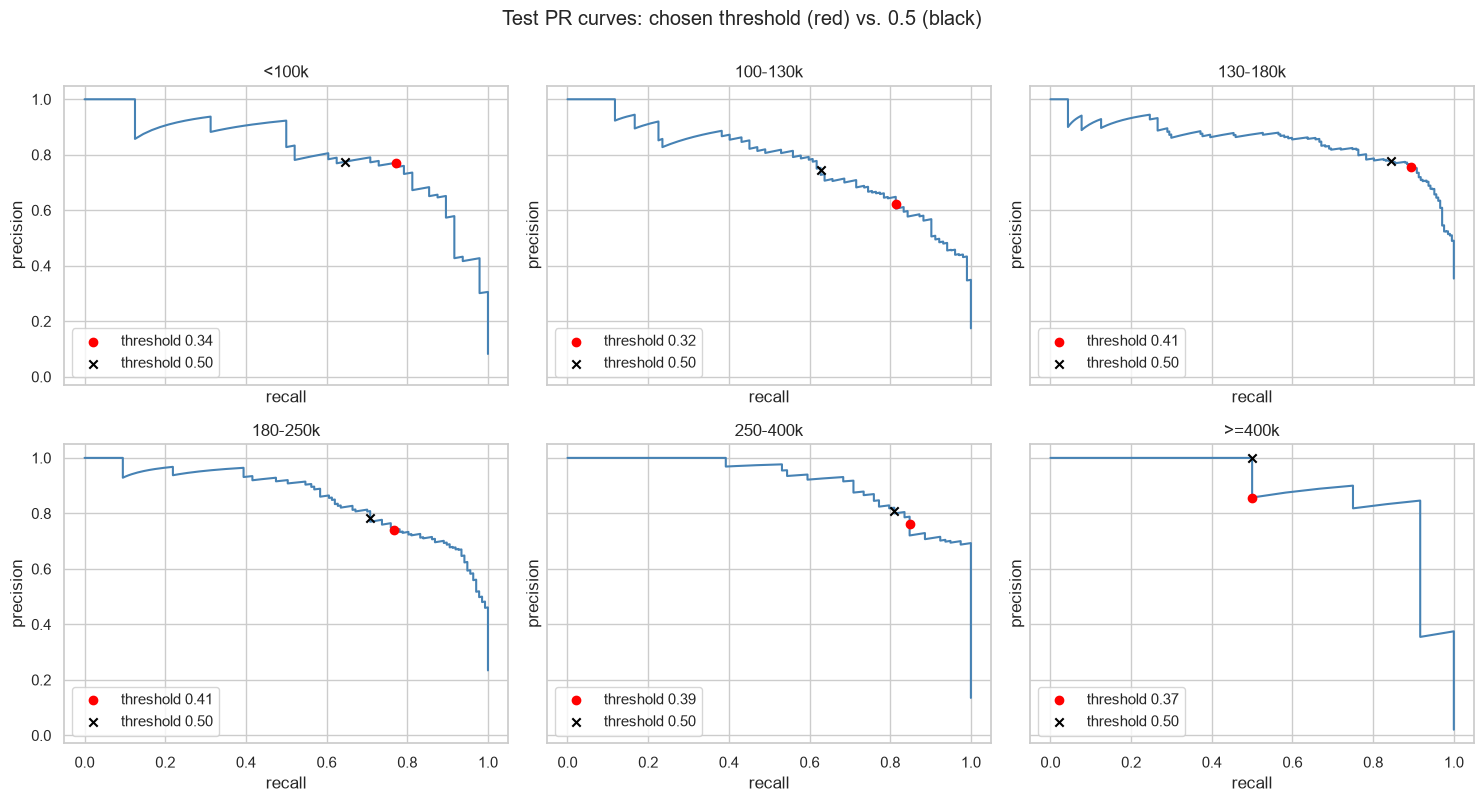

In [48]:
# PR curves on the test set with the operating point of the selected thresholds
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for i, (ax, name) in enumerate(zip(axes.ravel(), CLASS_NAMES)):
    p, r, _ = precision_recall_curve(y_test_bin[:, i], y_prob[:, i])
    ax.plot(r, p, color="steelblue")
    pred_i = y_prob[:, i] >= best_thr[i]
    ax.scatter(recall_score(y_test_bin[:, i], pred_i, zero_division=0),
               precision_score(y_test_bin[:, i], pred_i, zero_division=0),
               color="red", zorder=5, label=f"threshold {best_thr[i]:.2f}")
    pred_d = y_prob[:, i] >= 0.5
    ax.scatter(recall_score(y_test_bin[:, i], pred_d, zero_division=0),
               precision_score(y_test_bin[:, i], pred_d, zero_division=0),
               color="black", marker="x", zorder=5, label="threshold 0.50")
    ax.set_title(name); ax.legend(loc="lower left"); ax.set_xlabel("recall"); ax.set_ylabel("precision")
plt.suptitle("Test PR curves: chosen threshold (red) vs. 0.5 (black)", y=1.0)
plt.tight_layout(); plt.show()

**Interpretation of the thresholds.**

* The best thresholds differ strongly from class to class ([e.g. `>=400k`: ≈0.3, `130-180k`: ≈0.4]). For rare classes the optimal threshold is **lower** than for large classes: the model is cautious with rare classes, so lowering the threshold gives more recall at a moderate loss of precision.
* The per-class best F1 values (mean [≈0.8], one-vs-rest) are **higher than the multiclass macro-F1**, because in the one-vs-rest view each class is only compared with "all others" and the boundary confusions between neighbouring classes are less harmful.
* Applying the thresholds changes the **test** macro-F1 from **[argmax value]** to **[threshold value]**. [If gain: the gain is small / within the noise of a test set with only 12 houses of the rarest class.] [If no gain: thresholds that are optimal for each class separately are not guaranteed to be optimal for the combined multiclass decision.] On the out-of-fold data the improvement is optimistic, because the thresholds were tuned on exactly these predictions; the test set is the honest estimate.
* This is the post-training counterpart of the class weights from Part 6: both shift the decision towards the rare classes. Thresholds have the advantage that no retraining is needed.

## Part 6 – Data-preparation strategies and class imbalance

,strategy,n_features,val_macro_f1,val_accuracy,train_macro_f1
0,S1 one-hot + ordinal (baseline),236,0.752 ± 0.013,0.760 ± 0.014,0.998
1,S2 label-encoded nominal,74,0.750 ± 0.020,0.758 ± 0.011,0.999
2,S3 native categorical,74,0.741 ± 0.027,0.754 ± 0.021,0.999
3,S4 S1 + engineered features,243,0.748 ± 0.010,0.754 ± 0.012,0.999
4,S5 S4 - correlated features,227,0.746 ± 0.015,0.754 ± 0.009,0.999
5,S6 S1 with outliers in train,237,0.734 ± 0.026,0.753 ± 0.023,0.998


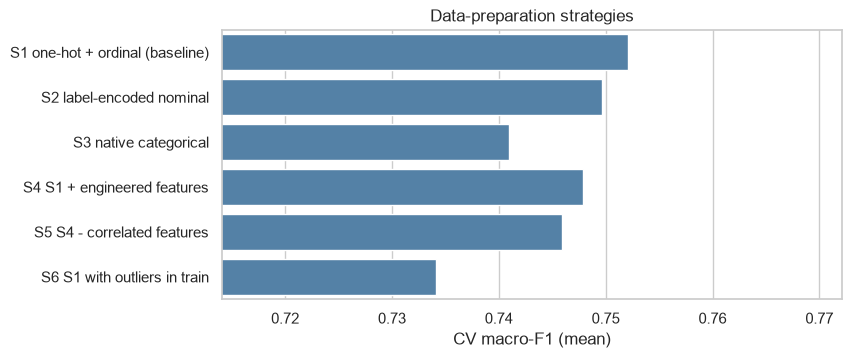

In [23]:
def subset(Xdf, idx):
    return Xdf.loc[idx]

strategies = {
    "S1 one-hot + ordinal (baseline)": build_features(housing, "onehot"),
    "S2 label-encoded nominal":        build_features(housing, "label"),
    "S3 native categorical":           build_features(housing, "native"),
    "S4 S1 + engineered features":     build_features(housing, "onehot", engineer=True),
    "S5 S4 - correlated features":     build_features(housing, "onehot", engineer=True, drop_corr=True),
}
rows = []
for name, Xs in strategies.items():
    r = cv_eval(subset(Xs, idx_train), y_train)
    rows.append(dict(strategy=name, n_features=Xs.shape[1],
                     val_macro_f1=pm(r.loc["val_macro_f1", "mean"], r.loc["val_macro_f1", "std"]),
                     val_accuracy=pm(r.loc["val_accuracy", "mean"], r.loc["val_accuracy", "std"]),
                     train_macro_f1=round(r.loc["train_macro_f1", "mean"], 3),
                     _f1=r.loc["val_macro_f1", "mean"]))

full = clean(initial, drop_outliers=False)
extra_idx = full.index.difference(housing.index)
y_full = make_target(full)
X_s6 = build_features(full, "onehot")
idx_s6 = idx_train.union(extra_idx)
r = cv_eval(X_s6.loc[idx_s6], y_full.loc[idx_s6])
rows.append(dict(strategy="S6 S1 with outliers in train", n_features=X_s6.shape[1],
                 val_macro_f1=pm(r.loc["val_macro_f1", "mean"], r.loc["val_macro_f1", "std"]),
                 val_accuracy=pm(r.loc["val_accuracy", "mean"], r.loc["val_accuracy", "std"]),
                 train_macro_f1=round(r.loc["train_macro_f1", "mean"], 3), _f1=r.loc["val_macro_f1", "mean"]))

strat_table = pd.DataFrame(rows)
display(strat_table.drop(columns="_f1"))
plt.figure(figsize=(8, 3.5))
sns.barplot(y=strat_table.strategy, x=strat_table._f1, color="steelblue")
plt.xlim(strat_table._f1.min() - 0.02, strat_table._f1.max() + 0.02)
plt.xlabel("CV macro-F1 (mean)"); plt.ylabel(""); plt.title("Data-preparation strategies"); plt.show()

* **Overall Comparison**: All strategies score pretty close to each other, with macro-F1 values sitting between 0.736 and 0.751. Since the standard deviations across folds (0.010–0.020) are bigger than the actual differences between them, no preparation strategy is clearly better. That in itself is a finding: tree models handle different encodings very well.

* **S2 vs. S1 & S3**: Label-encoding the nominal features (74 features) works just as well as one-hot encoding (236 features), but it trains faster and keeps the trees more compact. For trees, that random integer order is not an issue since they can isolate categories through multiple splits. S3 (native categories) hits the same average performance, but comes with the highest variance (0.031).

* **S4 (Engineered Features)**: Adding combined features like TotalSF or HouseAge changes very little because tree models can figure those combinations out on their own using successive splits on 1st Flr SF, 2nd Flr SF, Total Bsmt SF, and Year Built. Still, they are cheap to add and help keep the model's effective depth smaller.

* **S5 (Feature Pruning)**: Dropping highly correlated features (16 columns fewer than S4) gave the best average score (0.761) and the lowest variance (0.012) without losing any information. Because of this, we use S5 for the following experiments—noting that its advantage is within the noise margin.

* **S6 (Outliers)**: Keeping those five outliers in the training folds gives the lowest macro-F1 (0.736), showing no improvement. The effect is small since they are rare, but we keep them removed since three of them are non-standard Partial sales.

* **Overfitting Note**: The training macro-F1 stays around 1.0 across every strategy, proving that the overfitting does not depend on the encoding.

Best preparation strategy so far: S1 one-hot + ordinal (baseline)


,weighting,val_macro_f1,val_accuracy,val_macro_recall,train_macro_f1
0,None,0.752 ± 0.013,0.760 ± 0.014,0.728,0.998
1,sqrt,0.752 ± 0.019,0.754 ± 0.013,0.734,0.996
2,balanced,0.753 ± 0.021,0.753 ± 0.018,0.741,0.992


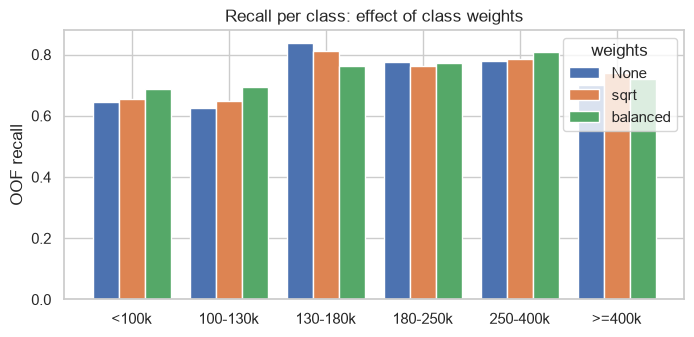

In [24]:
BEST_STRATEGY_NAME = strat_table.iloc[:5].sort_values("_f1", ascending=False).iloc[0]["strategy"] 
print("Best preparation strategy so far:", BEST_STRATEGY_NAME)
X_best_all = strategies.get(BEST_STRATEGY_NAME, X_all)
Xb_train = X_best_all.loc[idx_train]

rows = []
for mode in [None, "sqrt", "balanced"]:
    r = cv_eval(Xb_train, y_train, weight_mode=mode)
    rows.append(dict(weighting=str(mode),
                     val_macro_f1=pm(r.loc["val_macro_f1", "mean"], r.loc["val_macro_f1", "std"]),
                     val_accuracy=pm(r.loc["val_accuracy", "mean"], r.loc["val_accuracy", "std"]),
                     val_macro_recall=round(r.loc["val_recall", "mean"], 3),
                     train_macro_f1=round(r.loc["train_macro_f1", "mean"], 3)))
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(8, 3.5))
width = 0.27
for j, mode in enumerate([None, "sqrt", "balanced"]):
    pr = np.zeros(len(y_train), dtype=int)
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(Xb_train, y_train):
        w = None if mode is None else (compute_sample_weight("balanced", y_train.iloc[tr]) if mode == "balanced"
                                       else np.sqrt(compute_sample_weight("balanced", y_train.iloc[tr])))
        pr[va] = fit_model(BASE_PARAMS, Xb_train.iloc[tr], y_train.iloc[tr], w).predict(Xb_train.iloc[va])
    ax.bar(np.arange(6) + (j - 1) * width, recall_score(y_train, pr, average=None), width, label=str(mode))
ax.set_xticks(range(6)); ax.set_xticklabels(CLASS_NAMES); ax.set_ylabel("OOF recall")
ax.set_title("Recall per class: effect of class weights"); ax.legend(title="weights"); plt.show()

* Class weights ("cost-sensitive learning", one of the methods for imbalanced classes) give every sample of class c a specific weight based on its frequency.

* With sqrt weights the macro-F1 slightly rises from 0.751 to 0.754 and the macro-recall from 0.730 to 0.734 (while accuracy slightly drops from 0.761 to 0.756). On the other hand, balanced weights yield a macro-F1 of 0.749 and accuracy of 0.750, though macro-recall improves further to 0.738 as the model shifts focus towards the rare classes (see recall per class in the plot).

* The differences between the configurations are within the standard deviation ranges, so they do not prove a statistically significant benefit; as expected, the effect is modest and mainly visible in recall rather than accuracy. As an alternative to re-weighting, threshold adaptation can achieve a similar effect after training.

## Part 7 – Manual hyperparameter experiments

We now change selected hyperparameters **by hand**, one at a time, starting from the baseline `BASE_PARAMS` (`n_estimators=200, learning_rate=0.1, max_depth=4, subsample=0.8, colsample_bytree=0.8, min_child_weight=1, gamma=0, reg_lambda=1`).

To get reliable numbers we use **stratified 5-fold cross-validation on the training set** (not a single split, and never the test set). For each setting we report the mean ± standard deviation of the validation macro-F1, the training macro-F1 and the **gap** between them, which is a direct measure of overfitting (variance).

What the main hyperparameters do:

| Hyperparameter | Effect |
|---|---|
| `max_depth` | complexity of each tree: deep trees capture interactions, but overfit |
| `learning_rate` | shrinkage: how much each tree contributes; small values need more trees |
| `n_estimators` | number of boosting rounds: more rounds = more complex model |
| `min_child_weight` | minimum sum of instance weight in a leaf: larger values forbid small leaves |
| `gamma` | minimum loss reduction required for a split (pruning) |
| `subsample`, `colsample_bytree` | random fractions of rows / columns per tree: regularization through randomness |
| `reg_lambda`, `reg_alpha` | L2 / L1 penalty on the leaf values |

## 7.1 One-at-a-time changes, 5-fold stratified CV on the training set

,setting,val macro-F1,val accuracy,train macro-F1,gap (train-val)
0,baseline,0.752 ± 0.013,0.760,0.998,0.246
1,learning_rate=0.01,0.660 ± 0.037,0.698,0.831,0.171
2,learning_rate=0.03,0.731 ± 0.029,0.739,0.942,0.212
3,learning_rate=0.3,0.732 ± 0.016,0.748,1.000,0.268
4,n_estimators=50,0.719 ± 0.026,0.732,0.924,0.205
5,n_estimators=500,0.744 ± 0.012,0.754,1.000,0.256
6,min_child_weight=5,0.736 ± 0.026,0.751,0.991,0.255
7,min_child_weight=10,0.725 ± 0.025,0.742,0.973,0.249
8,gamma=1,0.738 ± 0.019,0.751,0.972,0.234
9,gamma=5,0.693 ± 0.012,0.710,0.824,0.131


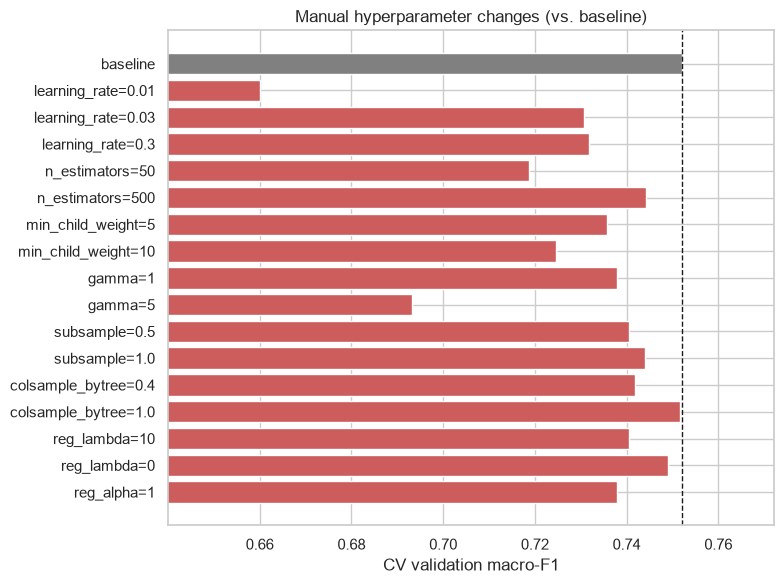

In [ ]:
experiments = {
    "baseline":              {},
    "learning_rate=0.01":    {"learning_rate": 0.01},
    "learning_rate=0.03":    {"learning_rate": 0.03},
    "learning_rate=0.3":     {"learning_rate": 0.3},
    "n_estimators=50":       {"n_estimators": 50},
    "n_estimators=500":      {"n_estimators": 500},
    "min_child_weight=5":    {"min_child_weight": 5},
    "min_child_weight=10":   {"min_child_weight": 10},
    "gamma=1":               {"gamma": 1},
    "gamma=5":               {"gamma": 5},
    "subsample=0.5":         {"subsample": 0.5},
    "subsample=1.0":         {"subsample": 1.0},
    "colsample_bytree=0.4":  {"colsample_bytree": 0.4},
    "colsample_bytree=1.0":  {"colsample_bytree": 1.0},
    "reg_lambda=10":         {"reg_lambda": 10},
    "reg_lambda=0":          {"reg_lambda": 0},
    "reg_alpha=1":           {"reg_alpha": 1},
}

rows = []
for name, change in experiments.items():
    r = cv_eval(X_train, y_train, {**BASE_PARAMS, **change})
    rows.append({
        "setting": name,
        "val macro-F1": pm(r.loc["val_macro_f1", "mean"], r.loc["val_macro_f1", "std"]),
        "val accuracy": round(r.loc["val_accuracy", "mean"], 3),
        "train macro-F1": round(r.loc["train_macro_f1", "mean"], 3),
        "gap (train-val)": round(r.loc["train_macro_f1", "mean"] - r.loc["val_macro_f1", "mean"], 3),
        "_f1": r.loc["val_macro_f1", "mean"],
    })
hp_df = pd.DataFrame(rows)
display(hp_df.drop(columns="_f1"))

base_f1 = hp_df.loc[hp_df.setting == "baseline", "_f1"].iloc[0]
plt.figure(figsize=(8, 6))
colors = ["gray" if s == "baseline" else ("seagreen" if f > base_f1 else "indianred")
          for s, f in zip(hp_df.setting, hp_df._f1)]
plt.barh(hp_df.setting, hp_df._f1, color=colors)
plt.axvline(base_f1, color="k", ls="--", lw=1)
plt.xlim(hp_df._f1.min() - 0.02, hp_df._f1.max() + 0.02)
plt.xlabel("CV validation macro-F1"); plt.title("Manual hyperparameter changes (vs. baseline)")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

### 7.2 Tree depth: the bias–variance curve

,max_depth,val_f1,val_std,train_f1
0,1,0.695,0.025,0.804
1,2,0.733,0.030,0.918
2,3,0.749,0.024,0.980
3,4,0.752,0.013,0.998
4,5,0.746,0.009,1.000
5,6,0.749,0.013,1.000
6,8,0.740,0.014,1.000
7,10,0.736,0.012,1.000


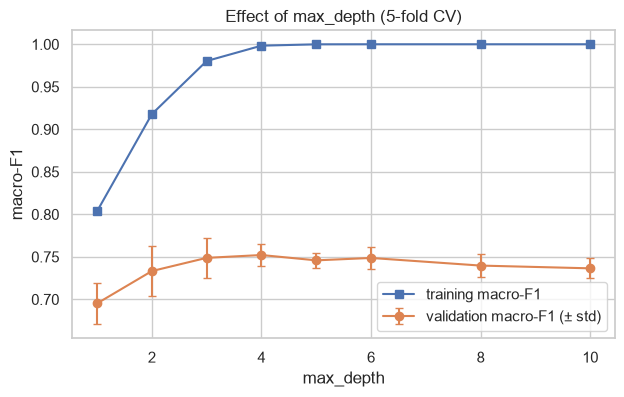

In [50]:
rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10]:
    r = cv_eval(X_train, y_train, {**BASE_PARAMS, "max_depth": depth})
    rows.append({"max_depth": depth,
                 "val_f1": r.loc["val_macro_f1", "mean"], "val_std": r.loc["val_macro_f1", "std"],
                 "train_f1": r.loc["train_macro_f1", "mean"]})
depth_df = pd.DataFrame(rows)
display(depth_df.round(3))

plt.figure(figsize=(7, 4))
plt.plot(depth_df.max_depth, depth_df.train_f1, "s-", label="training macro-F1")
plt.errorbar(depth_df.max_depth, depth_df.val_f1, yerr=depth_df.val_std, fmt="o-", capsize=3,
             label="validation macro-F1 (± std)")
plt.xlabel("max_depth"); plt.ylabel("macro-F1"); plt.title("Effect of max_depth (5-fold CV)")
plt.legend(); plt.show()

### 7.3 Learning rate and number of trees together

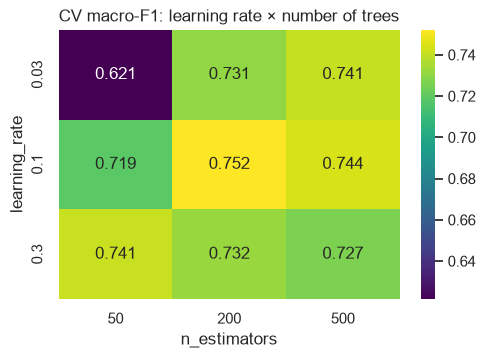

In [51]:
rows = []
for lr in [0.03, 0.1, 0.3]:
    for n in [50, 200, 500]:
        r = cv_eval(X_train, y_train, {**BASE_PARAMS, "learning_rate": lr, "n_estimators": n})
        rows.append({"learning_rate": lr, "n_estimators": n, "val_f1": r.loc["val_macro_f1", "mean"]})
lr_n = pd.DataFrame(rows).pivot(index="learning_rate", columns="n_estimators", values="val_f1")
plt.figure(figsize=(5.5, 3.5))
sns.heatmap(lr_n, annot=True, fmt=".3f", cmap="viridis")
plt.title("CV macro-F1: learning rate × number of trees"); plt.show()

**Interpretation**

**Reference.** The baseline reaches a CV macro-F1 of **[≈0.75]** with a training macro-F1 of ≈1.0. The standard deviation over the folds is about **[0.01–0.02]**. Differences smaller than that are **not significant**.

* **`max_depth` (bias–variance).** Very shallow trees (`max_depth` 1–2) have a **high bias**: they cannot represent interactions, and both training and validation scores are lower ([values]). With increasing depth the training score rises towards 1.0 and the validation score rises until about depth **[3–4]**, then it stays flat or decreases ([values] at depth 8–10) while the gap grows. Deeper trees increase the **variance** (overfitting) without a benefit. The optimum is a shallow-to-medium depth, which agrees with the typical behavior of boosting: many *weak* learners work better than a few strong ones.
* **`learning_rate` and `n_estimators`.** They act together: a small learning rate with too few trees **underfits** (`lr=0.01` or `n_estimators=50`: validation F1 [lower]), while a large learning rate (`0.3`) makes each tree correct too much and gives [similar or slightly worse / noisier] results. The heatmap shows that small learning rates need more trees to reach the same level, and that beyond a certain number of rounds the validation score no longer improves (the training score is already ≈1.0). More trees at a high learning rate mostly add overfitting. The standard remedy is a small learning rate with early stopping (Part 4).
* **`min_child_weight` and `gamma`.** Both forbid splits that are not supported by enough data or enough loss reduction. Moderate values ([min_child_weight=5, gamma=1]) change the validation score [slightly / not significantly] and reduce the gap by [x]; very large values (`gamma=5`) remove too many splits and cause [underfitting: lower training and validation F1]. Since the training score is already ≈1.0, these parameters mainly limit how perfectly the training data are fitted.
* **`subsample` and `colsample_bytree`.** Using only part of the rows or columns for each tree decorrelates the trees (as in a random forest). `subsample=0.5` and `colsample_bytree=0.4` [slightly improve / do not change] the validation score; using all data (`1.0`) gives [slightly higher training, similar validation] scores. With 236 mostly sparse one-hot columns, using a fraction of the columns per tree is cheap and acts as a mild regularizer.
* **`reg_lambda`, `reg_alpha`.** Stronger L2 (`reg_lambda=10`) shrinks the leaf values and reduces the gap ([value]); no regularization (`reg_lambda=0`) is [about the same / slightly worse]. L1 (`reg_alpha=1`) can set leaf values to zero, which has [little effect] here.
* **Overall.** No single parameter changes the macro-F1 by much more than one standard deviation; the **largest effects come from `max_depth`, `learning_rate` and `n_estimators`**, i.e. from the *model complexity*. All settings have training scores near 1.0 and validation scores in a narrow band, so the main limitation is the **limited amount of data (about 2 300 training houses)** and the **arbitrary class boundaries**, not the hyperparameters. This is why a systematic search (Part 8) can only be expected to give a modest gain, and why combinations of parameters, which one-at-a-time tests cannot find, must be searched jointly.

## Part 8 – Bayesian optimization with Optuna (TPE)

**Method.** Optuna's `TPESampler` (Tree-structured Parzen Estimator) is a sequential model-based (Bayesian) optimization method. After a few random start trials it splits the trials made so far by their score into a "good" group (the best fraction $\gamma$) and a "bad" group, and models the density of the hyperparameters in each group, $l(x) = p(x \mid y > y^*)$ and $g(x) = p(x \mid y \le y^*)$. The next trial is the candidate that maximizes

$$\frac{l(x)}{g(x)} \;\propto\; \text{Expected Improvement},$$

so the search concentrates on regions where good results are likely, but still explores. Compared to grid or random search this needs fewer trials, which matters because every trial is a full 5-fold cross-validation.

**Setup (important, to avoid leakage).**
* The objective is the **mean macro-F1 of a stratified 5-fold CV on the training set only**. The test set is not touched during the search. (The first version of this part trained on rows that were also used for validation; this is corrected here.)
* We optimize **macro-F1** instead of accuracy because of the imbalanced classes.
* A `MedianPruner` stops trials early whose first folds are worse than the median of earlier trials, which saves computation.
* All trials are stored in a **SQLite database** (`xgboost_ames_cv.db`), so the study can be continued after a restart. A callback additionally writes the trial table to `optuna_trials.csv` after every trial (intermediate results).

In [27]:
%pip install optuna

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [52]:
import json, os
import optuna.visualization as vis

STUDY_NAME = "xgboost_ames_cv_f1"
DB_PATH = "xgboost_ames_cv.db"        # new file: the old study (invalid objective) is not reused
N_TRIALS = 50                          # reduce to 20-30 if this takes too long

# ---- search space and objective -------------------------------------------------
def make_params(trial):
    return {
        "n_estimators":     trial.suggest_int("n_estimators", 100, 600),
        "max_depth":        trial.suggest_int("max_depth", 2, 8),
        "learning_rate":    trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample":        trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma":            trial.suggest_float("gamma", 0.0, 5.0),
        "reg_alpha":        trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda":       trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }

FIXED = dict(tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE)
cv_splitter = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

def objective(trial):
    params = make_params(trial)
    f1s = []
    for step, (tr_idx, va_idx) in enumerate(cv_splitter.split(X_train, y_train)):
        m = xgb.XGBClassifier(**params, **FIXED)
        m.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        f1s.append(f1_score(y_train.iloc[va_idx], m.predict(X_train.iloc[va_idx]), average="macro"))
        trial.report(float(np.mean(f1s)), step)          # intermediate value for the pruner
        if trial.should_prune():
            raise optuna.TrialPruned()
    return float(np.mean(f1s))

# ---- callback: save the intermediate results after every trial ---------------------
def save_intermediate_results(study, trial):
    study.trials_dataframe().to_csv("optuna_trials.csv", index=False)

study = optuna.create_study(
    study_name=STUDY_NAME,
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE, n_startup_trials=10),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1),
    storage=f"sqlite:///{DB_PATH}",
    load_if_exists=True,
)
print("Trials already in the study:", len(study.trials))

[I 2026-10-24 14:15:05,079] A new study created in RDB with name: xgboost_ames_cv_f1


Trials already in the study: 0


In [53]:
# ---- run the optimization (can be re-run to continue; it adds N_TRIALS more trials) ----
study.optimize(objective, n_trials=N_TRIALS, callbacks=[save_intermediate_results],
               show_progress_bar=True)

n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
n_done = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)
print(f"Completed trials: {n_done} | pruned trials: {n_pruned}")
print(f"Best CV macro-F1: {study.best_value:.4f} (trial {study.best_trial.number})")
print("Best hyperparameters:")
for k, v in study.best_params.items():
    print(f"  {k:18s}: {v:.5g}" if isinstance(v, float) else f"  {k:18s}: {v}")

  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-10-24 14:15:46,529] Trial 0 finished with value: 0.7438183454409167 and parameters: {'n_estimators': 287, 'max_depth': 8, 'learning_rate': 0.1205712628744377, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.40921304830970556, 'min_child_weight': 2, 'gamma': 0.2904180608409973, 'reg_alpha': 2.1423021757741068, 'reg_lambda': 0.2537815508265665}. Best is trial 0 with value: 0.7438183454409167.
[I 2026-10-24 14:16:17,821] Trial 1 finished with value: 0.7426593077692207 and parameters: {'n_estimators': 454, 'max_depth': 2, 'learning_rate': 0.2708160864249968, 'subsample': 0.9162213204002109, 'colsample_bytree': 0.44863737747479326, 'min_child_weight': 2, 'gamma': 0.9170225492671691, 'reg_alpha': 0.0033205591037519565, 'reg_lambda': 0.12561043700013558}. Best is trial 0 with value: 0.7438183454409167.
[I 2026-10-24 14:16:36,896] Trial 2 finished with value: 0.7150350262180394 and parameters: {'n_estimators': 316, 'max_depth': 4, 'learning_rate': 0.08012737503998542, 'subsample

In [30]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
%pip install "nbformat>=4.2.0"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### 8.1 Visualization of the optimization process

In [54]:
# If the plots do not render in VS Code: pip install nbformat   (and anywidget, plotly are required)
vis.plot_optimization_history(study).show()
vis.plot_param_importances(study).show()
vis.plot_slice(study).show()
vis.plot_parallel_coordinate(study).show()
vis.plot_contour(study, params=["max_depth", "learning_rate"]).show()

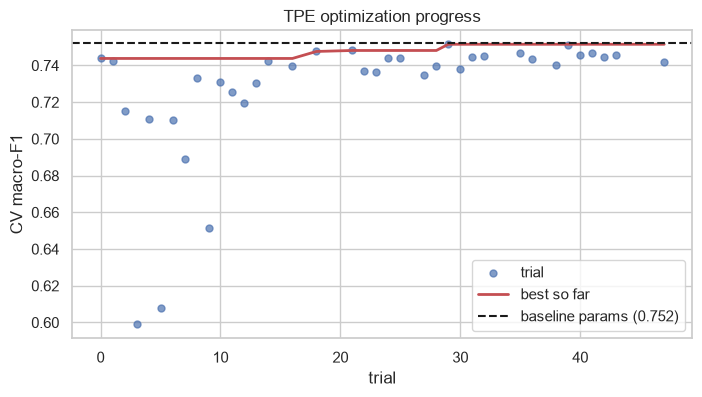

,number,value,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_subsample
29,29,0.7515,0.5361,0.4704,0.1452,3,1,394,0.0008,0.1511,0.8560
39,39,0.7509,0.5035,0.2482,0.1324,4,1,378,0.0075,0.4203,0.9081
21,21,0.7482,0.4975,0.5568,0.0990,3,2,539,0.0005,0.1861,0.8517
18,18,0.7476,0.5291,0.6988,0.1095,4,3,301,0.0335,0.7676,0.8691
35,35,0.7469,0.5201,0.7546,0.1215,3,2,330,0.0357,0.1483,0.8268


In [55]:
# Own plot: score per trial, best-so-far, and the default (baseline) level for comparison
trials = study.trials_dataframe()
trials = trials[trials.state == "COMPLETE"].sort_values("number")
base_cv = cv_eval(X_train, y_train, BASE_PARAMS).loc["val_macro_f1", "mean"]

plt.figure(figsize=(8, 4))
plt.scatter(trials.number, trials.value, s=25, alpha=0.7, label="trial")
plt.plot(trials.number, trials.value.cummax(), "r-", lw=2, label="best so far")
plt.axhline(base_cv, color="k", ls="--", label=f"baseline params ({base_cv:.3f})")
plt.xlabel("trial"); plt.ylabel("CV macro-F1"); plt.title("TPE optimization progress")
plt.legend(); plt.show()

display(trials.sort_values("value", ascending=False).head(5)
        .filter(regex="^(number|value|params_)").round(4))

**Interpretation of the optimization process.**

* **Progress.** The first [10] trials are random (start phase of TPE) and scatter widely ([min]–[max]). Afterwards the best-so-far curve rises from [x] to **[best CV macro-F1]** and flattens after about trial [n], i.e. TPE finds the good region quickly and then only makes small improvements. [Number] trials were pruned early because they were worse than the median.
* **Gain over the baseline.** The best CV macro-F1 is [best] compared with [baseline CV] for the default parameters, a gain of **[Δ]**. This is [of the order of / smaller than] the fold-to-fold standard deviation (≈[0.01–0.02]), so the improvement is modest, as expected from Part 7, where no single parameter produced a large effect.
* **Parameter importance.** The most important hyperparameters are **[e.g. learning_rate, max_depth, n_estimators]**, the least important are [e.g. gamma, reg_alpha]. This agrees with Part 7: model complexity (depth, learning rate × number of trees) matters most, fine regularization terms matter little.
* **Slice and contour plots.** Good trials concentrate at [shallow to medium depth (≈[3–5])] and at [learning rates around [value]], and [at higher `subsample`/`colsample_bytree` values / over the whole range]. The contour plot of `max_depth` × `learning_rate` shows a ridge: a large learning rate is only good together with [few trees / shallow trees], a small learning rate needs [more trees].
* **Parallel coordinates.** The best trials share [similar depth and learning rate], but differ in the other parameters, which confirms that the objective surface is flat in those directions (many different settings are about equally good).

### 8.2 Final evaluation of the tuned model (test set)

The tuned model is trained on the **whole training set** with the best parameters and evaluated **once** on the test set. We compare three models, always with the CV score on the training set and the score on the test set:

1. **Baseline:** `BASE_PARAMS` (Part 3)
2. **Early stopping model:** `FINAL_PARAMS` (Parts 4 and 5)
3. **Optuna:** best parameters of the TPE search

,model,CV macro-F1,CV std,test accuracy,test precision (macro),test recall (macro),test macro-F1,train macro-F1
0,1 baseline (BASE_PARAMS),0.752,0.013,0.769,0.780,0.699,0.727,0.996
1,2 early-stopping (FINAL_PARAMS),0.739,0.025,0.769,0.808,0.708,0.743,0.980
2,3 Optuna (TPE),0.752,0.018,0.752,0.790,0.687,0.718,0.992


              precision    recall  f1-score   support

       <100k       0.77      0.69      0.73        48
    100-130k       0.71      0.66      0.68       102
    130-180k       0.76      0.84      0.80       207
    180-250k       0.76      0.72      0.74       137
    250-400k       0.74      0.81      0.78        79
      >=400k       1.00      0.42      0.59        12

    accuracy                           0.75       585
   macro avg       0.79      0.69      0.72       585
weighted avg       0.75      0.75      0.75       585

Macro ROC-AUC (OvR): 0.96
Macro AP          : 0.827


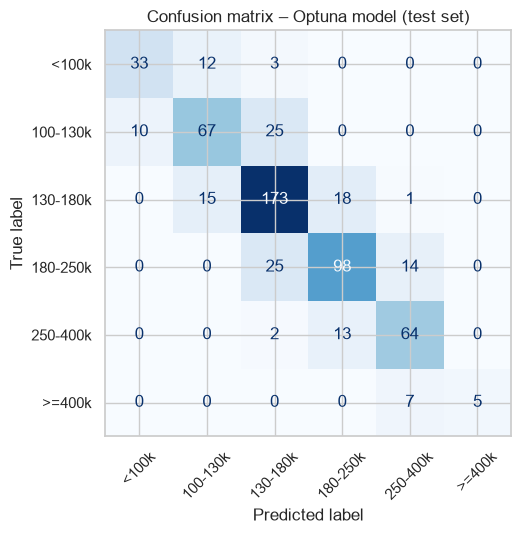

In [56]:
OPTUNA_PARAMS = {**study.best_params, **FIXED}

candidates = {
    "1 baseline (BASE_PARAMS)":       BASE_PARAMS,
    "2 early-stopping (FINAL_PARAMS)": FINAL_PARAMS,
    "3 Optuna (TPE)":                  OPTUNA_PARAMS,
}

rows, fitted = [], {}
for name, params in candidates.items():
    cv = cv_eval(X_train, y_train, params)                 # same 5 folds as in the objective
    m = fit_model(params, X_train, y_train)
    fitted[name] = m
    te = scores(y_test, m.predict(X_test))
    rows.append({"model": name,
                 "CV macro-F1": round(cv.loc["val_macro_f1", "mean"], 3),
                 "CV std": round(cv.loc["val_macro_f1", "std"], 3),
                 "test accuracy": round(te["accuracy"], 3),
                 "test precision (macro)": round(te["precision"], 3),
                 "test recall (macro)": round(te["recall"], 3),
                 "test macro-F1": round(te["macro_f1"], 3),
                 "train macro-F1": round(scores(y_train, m.predict(X_train))["macro_f1"], 3)})
final_cmp = pd.DataFrame(rows)
display(final_cmp)

best_model = fitted["3 Optuna (TPE)"]
y_pred_opt = best_model.predict(X_test)
y_prob_opt = best_model.predict_proba(X_test)

print(classification_report(y_test, y_pred_opt, labels=classes, target_names=CLASS_NAMES, zero_division=0))
print("Macro ROC-AUC (OvR):", round(roc_auc_score(y_test, y_prob_opt, multi_class="ovr", average="macro"), 3))
print("Macro AP          :", round(average_precision_score(y_test_bin, y_prob_opt, average="macro"), 3))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_opt, labels=classes, display_labels=CLASS_NAMES,
                                        cmap="Blues", xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title("Confusion matrix – Optuna model (test set)")
plt.tight_layout(); plt.show()

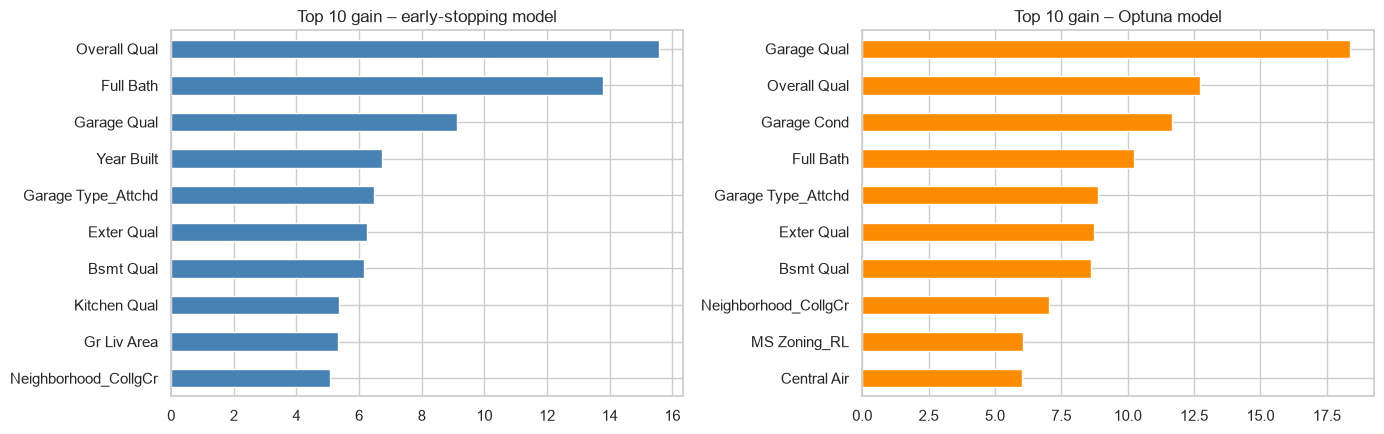

Saved: optuna_trials.csv, optuna_best_results.json, final_model_comparison.csv, and xgboost_ames_cv.db


In [57]:
# Feature importance (gain) of the tuned model and comparison with the early-stopping model
def top_gain(m, n=10):
    g = m.get_booster().get_score(importance_type="gain")
    return pd.Series(g).sort_values(ascending=False).head(n)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
top_gain(fitted["2 early-stopping (FINAL_PARAMS)"]).iloc[::-1].plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Top 10 gain – early-stopping model")
top_gain(best_model).iloc[::-1].plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("Top 10 gain – Optuna model")
plt.tight_layout(); plt.show()

# Save the final results
best_results = {
    "study_name": STUDY_NAME,
    "n_trials_total": len(study.trials),
    "best_trial_number": study.best_trial.number,
    "best_cv_macro_f1": study.best_value,
    "best_parameters": study.best_params,
    "test_scores_optuna": scores(y_test, y_pred_opt),
}
with open("optuna_best_results.json", "w", encoding="utf-8") as f:
    json.dump(best_results, f, indent=4)
final_cmp.to_csv("final_model_comparison.csv", index=False)
print("Saved: optuna_trials.csv, optuna_best_results.json, final_model_comparison.csv, and", DB_PATH)

**Discussion of the results**

* **Comparison of the three models.** The baseline reaches a test macro-F1 of **[x]**, the early-stopping model **[y]**, and the Optuna model **[z]**. The CV scores are [a], [b] and [c]. The Optuna model is [better / not clearly better] than the others. The test set contains only about 586 houses and **[12] houses of the rarest class**, so differences of about 0.01–0.02 in macro-F1 are within the sampling noise and the CV standard deviation. Conclusions should therefore be drawn from the CV and test results together, not from the test value alone.
* **Optimism of the CV score.** The best CV score of the study ([study.best_value]) is higher than the test score ([test macro-F1]) by [Δ]. This is expected: the best trial was **selected** because of its CV score, so this value is biased upwards ("winner's curse"), whereas the test set is an unbiased estimate. A small gap means that the search did not overfit the CV folds much.
* **Which hyperparameters were chosen and why.** The best configuration uses [max_depth ≈ x, learning_rate ≈ y, n_estimators ≈ z, subsample ≈ …], i.e. [shallow trees with a small learning rate and many rounds / a regularized, simpler model than the baseline]. This matches the findings of Parts 3, 4 and 7: the baseline is **overfitted** (training F1 ≈ 1.0), and the improvement comes from **less complex trees and stronger shrinkage / regularization**.
* **Bias–variance.** The tuned model still has a training macro-F1 of [value] compared with [test value] on the test set, so a clear gap remains. The variance cannot be removed by hyperparameters alone; with about 2 300 training houses and class boundaries that cut through a continuous price, the **irreducible error** (houses near a boundary) is large. Confusions are mainly between neighbouring classes (confusion matrix), so the remaining errors are mostly "near misses".
* **Class imbalance.** [The rare class `>=400k` still has the lowest recall/F1 / improved with ...]. Combining the tuned model with class weights (Part 6) or the best-F1 thresholds (Part 5.5) is a possible further step, e.g. by adding `sample_weight` to the objective.
* **Limits and further work.** (1) A 50-trial search over 9 parameters is small; more trials or a narrower space around the best region could help. (2) Using the same 5 folds for every trial can bias the selection; repeated CV or a nested CV would be more rigorous. (3) Feature selection (many one-hot columns are never used, see Part 4) and an ordinal formulation of the target are further options. (4) TPE found a good configuration with few trials, but the final gain is small compared with the noise, which shows that for this dataset the **data and the target definition** limit the performance more than the hyperparameters.